# Feature research

Workbench for the feature-selection questions in `PROGRESS.md`. The detector itself
stays in `features.py`; anything that wins here gets moved there and covered in `tests.py`.

Kernel: **RTCT Threat Detection (.venv)** (Python 3.11.16, pandas 3.0.6).

In [1]:
# Setup: point at the repo modules and confirm the kernel is the project venv.
import sys
from pathlib import Path

# Works whether the notebook is started from RTCT1/ or from Threat_Detection/.
HERE = Path.cwd()
for candidate in (HERE, HERE / "Threat_Detection"):
    if (candidate / "demo.py").exists():
        HERE = candidate
        break
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import data_io
import features
import local_paths

print("python       ", sys.version.split()[0], "|", sys.executable)
print("pandas       ", pd.__version__)
print("numpy        ", np.__version__)
print("modules from ", HERE)
ROOT = Path(local_paths.KUBEDATA_ROOT)
print("dataset root ", ROOT, "| exists:", ROOT.is_dir())

python        3.11.16 | /Users/cos/Documents/school/ECEN403/RTCT1/Threat_Detection/.venv/bin/python
pandas        3.0.6
numpy         2.4.6
modules from  /Users/cos/Documents/school/ECEN403/RTCT1/Threat_Detection
dataset root  /Users/cos/Library/CloudStorage/GoogleDrive-charles.sandlin@tamu.edu/.shortcut-targets-by-id/1ubCx1mP2Et0N3s3TGSI_uSlT1NtuFNpN/KUBEDATA | exists: True


In [2]:
# Read every capture once. The kernel keeps them, so later cells never touch Drive again.
manifest = data_io.build_manifest(ROOT)
print(f"{len(manifest)} captures | {manifest['label'].nunique()} labels"
      f" | {manifest['scenario'].nunique()} scenarios")

packets = {}
skipped = []
for row in manifest.itertuples():
    frame = data_io.load_capture(row.path)
    if not data_io.timebase_issues(frame)["usable"]:
        skipped.append((row.scenario, row.label, row.method))
        continue
    packets[(row.scenario, row.label, row.method)] = frame

rows = sum(len(frame) for frame in packets.values())
heap = sum(frame.memory_usage(deep=True).sum() for frame in packets.values()) / 2**20
print(f"loaded  {len(packets)} captures, {rows:,} packets, {heap:,.0f} MiB in memory")
print(f"skipped {len(skipped)} (bad timebase): {skipped}")

88 captures | 11 labels | 4 scenarios


loaded  87 captures, 5,978,304 packets, 897 MiB in memory
skipped 1 (bad timebase): [('nginx attack', 'pod-robot-controller', 'tcp')]


## Example measurement

`PROGRESS.md` flags `packet_count` / `total_bytes` as a redundancy to measure before
keeping both. Same harness works for any candidate: build features, compare per stratum.

In [3]:
# =============================================================================
# WHAT THIS MEASURES
#
# make_features() cuts one capture into 1-second windows, so every window gets
# packet_count (packets seen in that second) and total_bytes (their summed
# frame_len). This cell correlates those two per-window series WITHIN each
# capture, across that capture's ~42-69 windows, and reports Pearson r per stratum.
#
# WHY IT MATTERS
# detect_anomalies() scores a window as max|z| over the whole feature vector and
# flags it when any one feature passes 3 sigma. So a feature that is a near-copy of
# another can never be the top feature (no detection gained) but still counts toward
# that maximum (false alarms gained). PROGRESS.md lists this exact pair as "a
# redundancy worth measuring before keeping both".
#
# HOW TO READ r
#   r near  1.0  both columns carry the same information in that capture, so the
#                 second is dead weight: it changes no score, it only adds noise
#   r near  0.0  they move independently, so one can fire while the other reads normal
#   r below 0.0  more packets arrived with FEWER total bytes, i.e. a second of many
#                 tiny frames against a quiet second holding a few large ones
#
# Structural fact behind the suspicion: total_bytes == packet_count *
# mean_packet_size exactly (verified in the next cell), and all three are already in
# the 8-feature set. So total_bytes is the derivable column, not an independent
# measurement, and the open question is whether it is also a redundant one.
# =============================================================================
MIN_WINDOWS = 5  # below this many windows the correlation is noise, so skip the stratum

windows = {(s, l, m): features.make_windows(f) for (s, l, m), f in packets.items()}

redundancy = pd.DataFrame([
    {
        "scenario": s,
        "label": l,
        "method": m,
        "windows": len(w),
        "pearson_r": w["packet_count"].corr(w["total_bytes"]),
    }
    for (s, l, m), w in windows.items()
    if len(w) >= MIN_WINDOWS
])

print(f"packet_count vs total_bytes, one Pearson r per capture "
      f"({len(redundancy)} of {len(windows)} captures have >= {MIN_WINDOWS} windows)")
print()
print("per scenario:")
print(redundancy.groupby("scenario")["pearson_r"]
      .agg(["count", "mean", "min", "max"]).round(3).to_string())
print()
print("by capture method (tcpdump and ptcpdump see different kernel hook points):")
print(redundancy.groupby("method")["pearson_r"].mean().round(3).to_string())

# A mean near 1 reads as 'redundant', but it hides the strata that disagree with it.
# Count them, because the decision is per-feature across all strata, not per-mean.
interchangeable = redundancy["pearson_r"].gt(0.95).sum()
disagreeing = redundancy["pearson_r"].lt(0.5).sum()
print()
print(f"interchangeable (r > 0.95):      {interchangeable} of {len(redundancy)} strata")
print(f"break the assumption (r < 0.5):  {disagreeing} of {len(redundancy)} strata")
print()
print("strata where the two features disagree most, i.e. answer different questions:")
print(redundancy.nsmallest(6, "pearson_r").round(3).to_string(index=False))

packet_count vs total_bytes, one Pearson r per capture (86 of 87 captures have >= 5 windows)

per scenario:
                  count   mean    min    max
scenario                                    
benign               22  0.808 -0.432  1.000
injection attack     21  0.944  0.466  1.000
lidar attack         22  0.824  0.123  1.000
nginx attack         21  0.872  0.273  0.999

by capture method (tcpdump and ptcpdump see different kernel hook points):
method
ptcp    0.814
tcp     0.909

interchangeable (r > 0.95):      45 of 86 strata
break the assumption (r < 0.5):  9 of 86 strata

strata where the two features disagree most, i.e. answer different questions:
        scenario       label method  windows  pearson_r
          benign   pod-lidar   ptcp       58     -0.432
    lidar attack node-child1   ptcp       61      0.123
          benign node-child1   ptcp       60      0.128
    nginx attack node-child1   ptcp       69      0.273
    lidar attack   pod-lidar   ptcp       62      0.33

In [4]:
# =============================================================================
# WHY THE SPREAD EXISTS
#
# The pair only behaves redundantly while packet sizes stay steady. When a capture's
# per-window mean packet size swings, packets and bytes stop tracking each other: a
# burst of tiny frames (RST/SYN/keepalive/ARP) adds many packets and few bytes, which
# drives r down and can drive it negative.
#
# Test that explanation two ways: (1) confirm the algebraic identity that makes
# total_bytes a derived column at all, and (2) check whether a capture's own packet
# size variability predicts its r.
# =============================================================================
check = pd.DataFrame([
    {
        "scenario": s,
        "label": l,
        "method": m,
        "identity_error": (w["packet_count"] * w["mean_packet_size"]
                           - w["total_bytes"]).abs().max(),
        "size_cv": w["mean_packet_size"].std() / w["mean_packet_size"].mean(),
        "pearson_r": w["packet_count"].corr(w["total_bytes"]),
    }
    for (s, l, m), w in windows.items()
    if len(w) >= MIN_WINDOWS
])

print("1. is total_bytes a derived column?")
print(f"   worst |packet_count * mean_packet_size - total_bytes| over all captures:"
      f" {check['identity_error'].max():.2e}")
print("   that is float rounding, so yes: the third number is the product of two others")
print()
print("2. does packet-size variability explain the low r?")
print(f"   corr(size_cv, pearson_r) = {check['size_cv'].corr(check['pearson_r']):.3f}")
print("   negative, so the captures whose window-to-window packet size swings most are")
print("   exactly the ones where packet_count and total_bytes stop agreeing.")
print()
print("so total_bytes is a derived column, and it stands in for packet_count only")
print("while packet size is steady. Keeping packet_count + mean_packet_size spans the")
print("same three-way information without that ambiguity. That is a hypothesis for the")
print("next measurement, not a result.")

1. is total_bytes a derived column?
   worst |packet_count * mean_packet_size - total_bytes| over all captures: 1.19e-07
   that is float rounding, so yes: the third number is the product of two others

2. does packet-size variability explain the low r?
   corr(size_cv, pearson_r) = -0.409
   negative, so the captures whose window-to-window packet size swings most are
   exactly the ones where packet_count and total_bytes stop agreeing.

so total_bytes is a derived column, and it stands in for packet_count only
while packet size is steady. Keeping packet_count + mean_packet_size spans the
same three-way information without that ambiguity. That is a hypothesis for the
next measurement, not a result.


## Redundancy across all 8 features

The pair above is one suspicion. A correlation matrix over all 28 feature pairs is the
same check run everywhere at once. It has to be computed per capture and then
aggregated, never by pooling windows from all 87 captures into one table.

86 captures x 13 features = 78 pairs

pairs that duplicate each other most, ranked by share of captures at |r| > 0.95:
     feature_a        feature_b  mean_r  redundant_frac
  packet_count      total_bytes   0.861           0.523
   total_bytes    payload_bytes   0.715           0.360
    http_count        http_frac   0.788           0.186
  packet_count    payload_bytes   0.638           0.174
   total_bytes mean_packet_size   0.798           0.140
unique_dst_ips unique_dst_ports   0.799           0.116
     syn_count        rst_count   0.600           0.116
  packet_count unique_dst_ports   0.237           0.105
   total_bytes unique_dst_ports   0.149           0.081
   total_bytes        dns_count   0.135           0.070


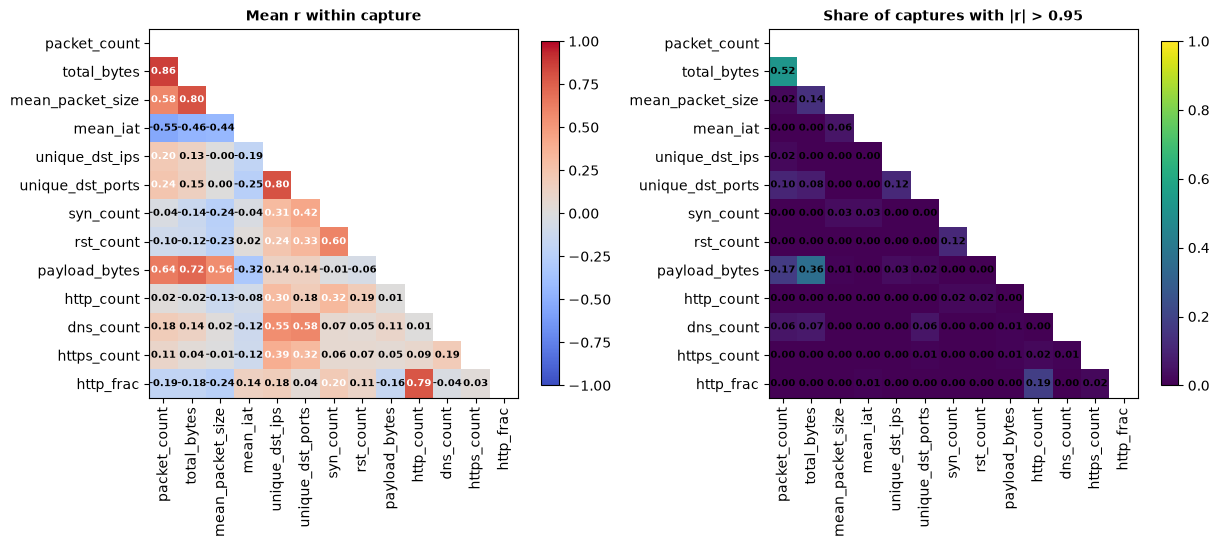

In [5]:
# =============================================================================
# WHAT THIS MEASURES
#
# All 28 pairwise correlations among the 8 detector features. Each correlation is
# computed WITHIN one capture (Pearson r over that capture's windows), then the 86
# captures are aggregated into two summaries:
#
#   mean_r          average r of the pair across the captures where it is defined
#   redundant_frac  share of captures where |r| > 0.95, i.e. the pair is a copy there
#
# WHY NOT ONE POOLED MATRIX
# Pooling every window from every capture makes r report capture identity instead of
# feature behaviour: pod-nginx carries 346 packets in total and router-any 263,000, so
# a pooled matrix mostly says that large captures are large. Correlating inside a
# capture and aggregating afterwards keeps the question at "do these two features move
# together within the same measurement", which is the question the detector faces.
#
# WHY IT MATTERS FOR THE DETECTOR
# The score is max|z| over the feature vector, so a pair sitting at r ~ 1 is one vote
# counted twice: no extra detection, extra false alarms. redundant_frac near 1.0 means
# the pair is a duplicate in every measurement and one of the two can be dropped.
# =============================================================================
FEATURES = list(features.FEATURE_LABELS)
n = len(FEATURES)

per_capture = [w[FEATURES].corr() for (s, l, m), w in windows.items()
               if len(w) >= MIN_WINDOWS]
stacked = np.dstack([c.to_numpy() for c in per_capture])   # (feature, feature, capture)

mean_r = pd.DataFrame(np.nanmean(stacked, axis=2), index=FEATURES, columns=FEATURES)
redundant_frac = pd.DataFrame((np.abs(stacked) > 0.95).mean(axis=2),
                              index=FEATURES, columns=FEATURES)
print(f"{len(per_capture)} captures x {n} features = {n * (n - 1) // 2} pairs")

# Rank the pairs so the answer is numbers, not just colour. A high mean_r with a low
# redundant_frac means the pair duplicates itself in some captures and not others.
pairs = pd.DataFrame([
    {
        "feature_a": FEATURES[i],
        "feature_b": FEATURES[j],
        "mean_r": mean_r.iat[i, j],
        "redundant_frac": redundant_frac.iat[i, j],
    }
    for i in range(n) for j in range(i + 1, n)
]).sort_values("redundant_frac", ascending=False)

print()
print("pairs that duplicate each other most, ranked by share of captures at |r| > 0.95:")
print(pairs.head(10).round(3).to_string(index=False))

# Upper triangle masked: the matrix is symmetric, so half of it is repetition.
mask = np.triu(np.ones((n, n), dtype=bool))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.6))
for ax, matrix, title, cmap, vmin, vmax, fmt in [
    (axes[0], mean_r, "Mean r within capture", "coolwarm", -1.0, 1.0, ".2f"),
    (axes[1], redundant_frac, "Share of captures with |r| > 0.95", "viridis", 0.0, 1.0, ".2f"),
]:
    shown = np.ma.masked_where(mask, matrix.to_numpy())
    image = ax.imshow(shown, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(n), FEATURES, rotation=90)
    ax.set_yticks(range(n), FEATURES)
    ax.set_title(title, fontsize=10, fontweight="bold")
    fig.colorbar(image, ax=ax, shrink=0.8)
    for i in range(n):
        for j in range(n):
            if not mask[i, j] and np.isfinite(shown[i, j]):
                ax.text(j, i, format(shown[i, j], fmt), ha="center", va="center",
                        fontsize=7, fontweight="bold",
                        color="white" if abs(shown[i, j] - vmin) > (vmax - vmin) * 0.6 else "black")
fig.tight_layout()
plt.show()

## Why only 8 features?

Nothing selected them. `FEATURE_LABELS` holds the aggregates that existed in the first
version of `features.py`, built from the 7 columns in `PACKET_COLUMNS`. The CSVs carry 34
columns. The cells below build a candidate feature for every aggregatable column, drop the
ones that are constant or empty, and correlate what is left.

In [6]:
# =============================================================================
# THE FULL FEATURE POOL
#
# The 8 features in features.py were never selected: they were the aggregates that
# existed when the detector was first written, built from the 7 columns in
# PACKET_COLUMNS. The CSVs carry 34 columns, so this cell builds a candidate
# feature for every column that can be aggregated into a 1-second window, then
# measures which candidates are actually usable.
#
# A candidate is only worth a correlation slot if it VARIES within a capture. A
# column that is constant, or empty, in most captures cannot separate anything no
# matter how it correlates, so the availability table is the first gate and the
# matrix in the next cell only covers survivors.
#
# Why the pool matters: 7 of the 8 current features exist only in these packet
# CSVs. Subsystem 1's Prometheus surface exposes pod CPU/memory and node memory
# with network RX removed, so a feature that is only obtainable here cannot feed
# the FSR's baseline-to-detection interface. A bigger pool is not free: every
# candidate added is one more thing that must be obtainable at a vantage worth
# instrumenting.
# =============================================================================
WIDE_COLUMNS = [
    "ts", "iat", "frame_len", "src_ip", "dst_ip", "src_port", "dst_port",
    "proto", "ip_version", "ttl_or_hlim", "arp_opcode", "icmp_type",
    "is_dns", "is_http", "is_https", "udp_length", "tcp_payload_len",
    "tcp_ack", "tcp_fin", "tcp_psh", "tcp_syn", "tcp_rst",
    "tcp_urg", "tcp_ece", "tcp_cwr",
]


def make_wide_features(packets, window=features.WINDOW_SIZE):
    """Per-1s-window aggregates over every usable CSV column.

    Exploratory: this lives in the notebook until a feature earns a place in
    features.make_windows(), at which point it moves there and gets a test.
    """
    frame = packets
    frame = frame.assign(time_bin=((frame["ts"] - frame["ts"].min()) // window).astype(int))

    # Per-packet columns the CSV does not carry, needed for the diversity counts.
    frame = frame.assign(
        flow_dst=frame["dst_ip"].astype(str) + ":" + frame["dst_port"].fillna(-1).astype("int64").astype(str),
        flow_src=frame["src_ip"].astype(str) + ":" + frame["src_port"].fillna(-1).astype("int64").astype(str),
    )
    # proto is a STRING column with mixed labels ("tcp", "udp", "icmp") and numeric
    # strings for the rest ("58" is ICMPv6, "2" is IGMP), so match on text.
    proto = frame["proto"].fillna("none").astype(str).str.lower()
    icmp_like = proto.isin(["icmp", "1", "58"])
    frame = frame.assign(
        p_tcp=proto.eq("tcp").astype(int),
        p_udp=proto.eq("udp").astype(int),
        p_icmp=icmp_like.astype(int),
        p_other=(~proto.isin(["tcp", "udp", "icmp", "1", "58"])).astype(int),
        is_arp=frame["arp_opcode"].notna().astype(int),
        is_ipv6=frame["ip_version"].eq(6).astype(int),
    )

    grouped = frame.groupby("time_bin")
    out = pd.DataFrame({
        # volume and size
        "packet_count":      grouped.size(),
        "total_bytes":       grouped["frame_len"].sum(),
        "mean_packet_size":  grouped["frame_len"].mean(),
        "std_packet_size":   grouped["frame_len"].std(),
        "udp_bytes":         grouped["udp_length"].sum(min_count=1),
        "payload_bytes":     grouped["tcp_payload_len"].sum(min_count=1),
        # timing
        "mean_iat":          grouped["iat"].mean(),
        "std_iat":           grouped["iat"].std(),
        "mean_ttl":          grouped["ttl_or_hlim"].mean(),
        # addressing and port diversity, both directions
        "unique_src_ips":    grouped["src_ip"].nunique(),
        "unique_dst_ips":    grouped["dst_ip"].nunique(),
        "unique_src_ports":  grouped["src_port"].nunique(),
        "unique_dst_ports":  grouped["dst_port"].nunique(),
        "unique_src_flows":  grouped["flow_src"].nunique(),
        "unique_dst_flows":  grouped["flow_dst"].nunique(),
        # protocol mix
        "tcp_count":         grouped["p_tcp"].sum(),
        "udp_count":         grouped["p_udp"].sum(),
        "icmp_count":        grouped["p_icmp"].sum(),
        "other_proto_count": grouped["p_other"].sum(),
        "ipv6_count":        grouped["is_ipv6"].sum(),
        "arp_count":         grouped["is_arp"].sum(),
        "dns_count":         grouped["is_dns"].sum(),
        "http_count":        grouped["is_http"].sum(),
        "https_count":       grouped["is_https"].sum(),
        # tcp flags
        "syn_count":         grouped["tcp_syn"].sum(),
        "rst_count":         grouped["tcp_rst"].sum(),
        "ack_count":         grouped["tcp_ack"].sum(),
        "fin_count":         grouped["tcp_fin"].sum(),
        "psh_count":         grouped["tcp_psh"].sum(),
        "urg_count":         grouped["tcp_urg"].sum(),
        "ece_count":         grouped["tcp_ece"].sum(),
        "cwr_count":         grouped["tcp_cwr"].sum(),
    })
    # Ratios, so a busy second and a quiet one can be compared on composition.
    out["payload_ratio"] = out["payload_bytes"] / out["total_bytes"].replace(0, np.nan)
    out["tcp_share"] = out["tcp_count"] / out["packet_count"]
    out["udp_share"] = out["udp_count"] / out["packet_count"]
    out["icmp_share"] = out["icmp_count"] / out["packet_count"]
    return out.sort_index()


# Read the wide columns per capture and keep ONLY the window frames, so peak memory
# stays near one capture instead of all 6.2M rows (the 7-column load in the cell
# above already holds ~669 MiB).
wide = {}
wide_skipped = []
for row in manifest.itertuples():
    packets_wide = pd.read_csv(row.path, usecols=WIDE_COLUMNS, low_memory=False)
    if not data_io.timebase_issues(packets_wide)["usable"]:
        wide_skipped.append((row.scenario, row.label, row.method))
        continue
    wide[(row.scenario, row.label, row.method)] = make_wide_features(packets_wide)

WIDE_FEATURES = list(next(iter(wide.values())).columns)
print(f"{len(wide)} captures x {len(WIDE_FEATURES)} candidate features "
      f"= {len(WIDE_FEATURES) * (len(WIDE_FEATURES) - 1) // 2} pairs")
print(f"skipped {len(wide_skipped)} (bad timebase): {wide_skipped}")

# Availability gate, before any correlation: in how many captures is this feature
# both defined and non-constant? A constant feature has no variance, so its
# z-score is 0 or infinite and it cannot rank windows.
availability = pd.DataFrame([
    {
        "feature": feature,
        "defined_in": int(sum(np.isfinite(w[feature]).any() for w in wide.values())),
        "varying_in": int(sum(
            np.isfinite(w[feature]).sum() > 1 and w[feature].std() > 0
            for w in wide.values()
        )),
        "dead_in": int(sum(not (np.isfinite(w[feature]).sum() > 1 and w[feature].std() > 0)
                           for w in wide.values())),
    }
    for feature in WIDE_FEATURES
])
availability["varying_share"] = (availability["varying_in"] / len(wide)).round(3)
availability = availability.sort_values(["varying_in", "defined_in"])
print()
print("candidate features, fewest usable captures first:")
print(availability.to_string(index=False))

87 captures x 36 candidate features = 630 pairs
skipped 1 (bad timebase): [('nginx attack', 'pod-robot-controller', 'tcp')]



candidate features, fewest usable captures first:
          feature  defined_in  varying_in  dead_in  varying_share
        urg_count          87           0       87          0.000
        ece_count          87           0       87          0.000
        cwr_count          87           0       87          0.000
        rst_count          87          50       37          0.575
       icmp_count          87          61       26          0.701
       icmp_share          87          61       26          0.701
      https_count          87          62       25          0.713
        arp_count          87          63       24          0.724
       http_count          87          63       24          0.724
       ipv6_count          87          66       21          0.759
        dns_count          87          70       17          0.805
        fin_count          87          71       16          0.816
other_proto_count          87          72       15          0.828
        udp_bytes        

33 of 36 candidates vary in at least 50% of captures
excluded as dead: ['urg_count', 'ece_count', 'cwr_count']

every feature's nearest neighbour (max_abs_r near 1.0 and closest_frac near 1.0
means it is a duplicate; a high mean_abs_r alone just means it tracks volume):
                   mean_abs_r  max_abs_r    closest_feature  closest_frac
ack_count               0.295      0.999          tcp_count         0.943
tcp_count               0.295      0.999          ack_count         0.943
payload_bytes           0.289      0.993        total_bytes         0.862
total_bytes             0.306      0.993      payload_bytes         0.862
unique_src_ports        0.313      0.991   unique_src_flows         0.954
unique_src_flows        0.316      0.991   unique_src_ports         0.954
unique_dst_ports        0.318      0.987   unique_dst_flows         0.954
unique_dst_flows        0.319      0.987   unique_dst_ports         0.954
unique_src_ips          0.281      0.968     unique_dst_ips    

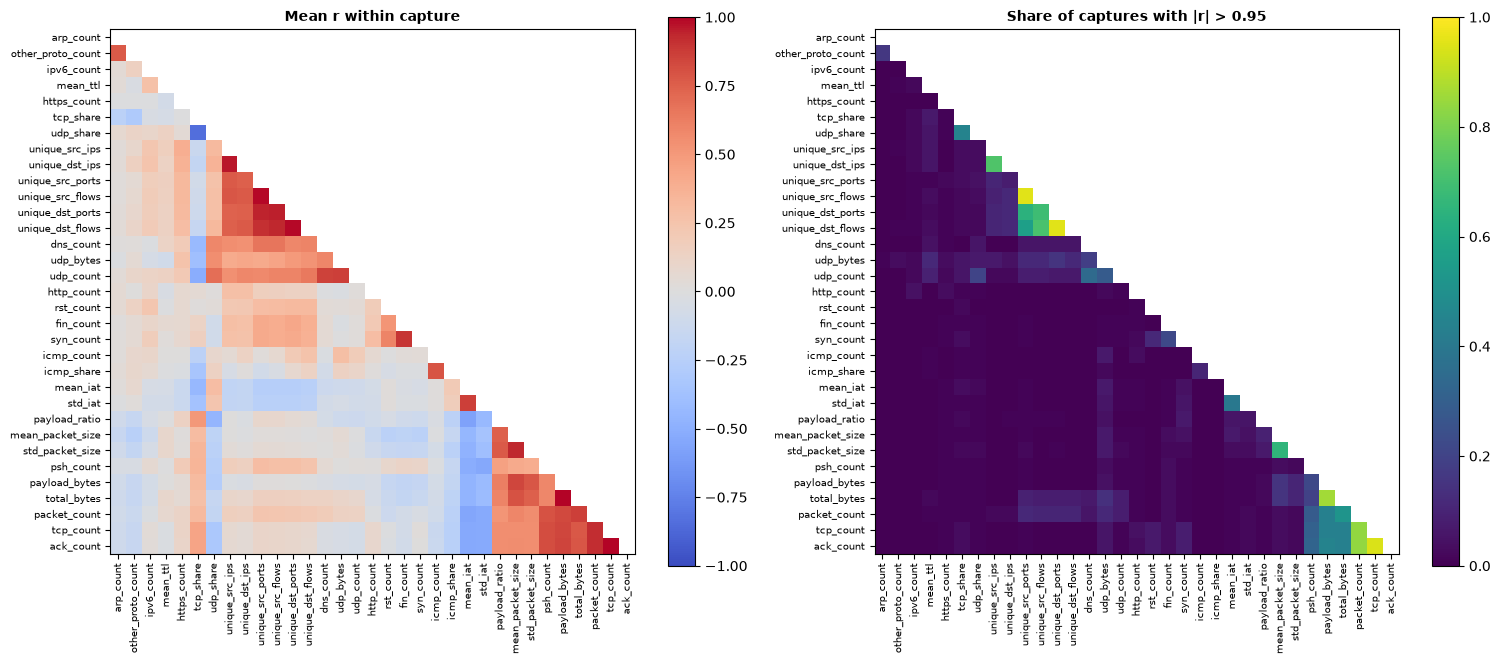

In [7]:
# =============================================================================
# CORRELATION ACROSS THE WHOLE POOL
#
# Same method as the 8-feature matrix above: correlate WITHIN each capture, then
# aggregate over captures. Never pool windows from different captures, or r reports
# which capture a window came from instead of which features move together.
#
# Two summaries per pair:
#   mean_r   average r over the captures where the pair is defined
#   frac     share of captures where |r| > 0.95, i.e. the pair is a copy there
#
# Features are ordered by hierarchical clustering on (1 - |r|), so groups of
# mutually redundant features form visible blocks. Rows and columns share that
# order; both panels use it.
#
# Two things to expect in the result, and neither is a bug:
#   1. A large block of raw COUNT features (packet_count, tcp_count, ack_count,
#      syn_count, total_bytes...) correlates with itself on any busy second. They
#      share a traffic-volume factor. A high r there means "both track volume",
#      not "one is a copy of the other", and the usual fix is to normalise into a
#      rate or a share rather than to delete one.
#   2. Very few pairs reach |r| > 0.95, which is the bar for an actual duplicate.
#
# Per-cell numbers are omitted: at this feature count they are unreadable, so read
# the blocks and take exact values from the table printed below.
# =============================================================================
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

# Availability gate: a feature constant in more than half the captures cannot rank
# windows in those captures, so it is not allowed to shape the matrix.
USABLE_AT_LEAST = 0.5
usable = availability.loc[availability["varying_share"] >= USABLE_AT_LEAST, "feature"].tolist()
excluded = [f for f in WIDE_FEATURES if f not in usable]
n_wide = len(usable)
print(f"{n_wide} of {len(WIDE_FEATURES)} candidates vary in at least "
      f"{USABLE_AT_LEAST:.0%} of captures")
print(f"excluded as dead: {excluded}")

wide_corr = [w[usable].corr() for w in wide.values()]
stacked_wide = np.dstack([c.to_numpy() for c in wide_corr])
mean_r_wide = pd.DataFrame(np.nanmean(stacked_wide, axis=2), index=usable, columns=usable)
frac_wide = pd.DataFrame((np.abs(stacked_wide) > 0.95).mean(axis=2), index=usable, columns=usable)

# Cluster order. Undefined pairs get distance 1 (neutral) so they do not pull the
# dendrogram together.
distance = (1.0 - mean_r_wide.abs().fillna(0.0)).to_numpy(copy=True)
np.fill_diagonal(distance, 0.0)
order = leaves_list(linkage(squareform(distance, checks=False), method="average"))
ordered = [usable[i] for i in order]
mean_r_wide = mean_r_wide.loc[ordered, ordered]
frac_wide = frac_wide.loc[ordered, ordered]

# Which feature is closest to being a copy of another, and of what.
off_diagonal = mean_r_wide.where(~np.eye(n_wide, dtype=bool))
summary = pd.DataFrame({
    "mean_abs_r": off_diagonal.abs().mean(axis=1),
    "max_abs_r": off_diagonal.abs().max(axis=1),
    "closest_feature": off_diagonal.abs().idxmax(axis=1),
    "closest_frac": [frac_wide.loc[f, off_diagonal.abs().idxmax(axis=1)[f]] for f in mean_r_wide.index],
}).sort_values("max_abs_r", ascending=False)

print()
print("every feature's nearest neighbour (max_abs_r near 1.0 and closest_frac near 1.0")
print("means it is a duplicate; a high mean_abs_r alone just means it tracks volume):")
print(summary.round(3).to_string())

mask_wide = np.triu(np.ones((n_wide, n_wide), dtype=bool))
fig, axes = plt.subplots(1, 2, figsize=(15.5, 7.8))
for ax, matrix, title, cmap, vmin, vmax in [
    (axes[0], mean_r_wide, "Mean r within capture", "coolwarm", -1.0, 1.0),
    (axes[1], frac_wide, "Share of captures with |r| > 0.95", "viridis", 0.0, 1.0),
]:
    shown = np.ma.masked_where(mask_wide, matrix.to_numpy())
    image = ax.imshow(shown, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_xticks(range(n_wide), ordered, rotation=90, fontsize=7)
    ax.set_yticks(range(n_wide), ordered, fontsize=7)
    ax.set_title(title, fontsize=10, fontweight="bold")
    fig.colorbar(image, ax=ax, shrink=0.75)

fig.tight_layout()
fig.savefig(data_io.resolve_output("feature_correlation_all.png"), dpi=150)
plt.show()

In [8]:
# =============================================================================
# WHAT EACH CANDIDATE IS WORTH
#
# The correlation matrix says which features are copies of each other. It says
# nothing about whether a feature DISCRIMINATES: an independent feature can still
# be pure noise. This cell answers the other half by reusing the two metrics in
# feature_value.py, unchanged, over the wide pool instead of the 8:
#
#   auc              threshold-free separation between attack and benign windows.
#                    0.5 = coin flip, 1.0 = perfect. No model, no threshold, so
#                    features are compared fairly.
#   detection_at_5pct  share of attack windows one feature flags when its cutoff is
#                    set to flag 5% of that stratum's held-out benign windows. This
#                    is the calibrated comparison z-score's fixed 3 sigma never had.
#
# Both are measured against the matched benign reference for the same capture label
# and capture method, so no feature is credited for a vantage effect. Each feature
# gets the same 65 (stratum x scenario) rows as the 8-feature run: 22 injection +
# 22 lidar + 21 nginx, the nginx pod-robot-controller tcp capture being the one
# excluded for a bad timebase.
# =============================================================================
import feature_value as fv
import sweep

POOL_STRONG_AUC = fv.STRONG_AUC   # 0.75, same bar as the 8-feature run


def rank_pool(pool):
    """feature_value.rank_features, re-pointed at the wide pool."""
    scenarios = sorted({key[0] for key in pool} - {"benign"})
    rows = []
    for method in sorted({key[2] for key in pool}):
        for label in sorted({key[1] for key in pool}):
            reference = pool.get(("benign", label, method))
            if reference is None:
                continue
            try:
                train, holdout = sweep.split_reference(reference)
            except ValueError:      # too few benign windows to split
                continue
            for scenario in scenarios:
                target = pool.get((scenario, label, method))
                if target is None:
                    continue
                for feature in reference.columns:
                    rows.append({
                        "feature": feature,
                        "scenario": scenario,
                        "label": label,
                        "method": method,
                        "auc": fv.separation_auc(holdout[feature], target[feature]),
                        "detection_at_5pct": fv.detection_at_budget(
                            train[feature], holdout[feature], target[feature]),
                        "benign_windows": int(holdout[feature].notna().sum()),
                        "attack_windows": int(target[feature].notna().sum()),
                    })
    return pd.DataFrame(rows)


pool_value = rank_pool(wide)
pool_value.to_csv(data_io.resolve_output("feature_value_wide.csv"), index=False)
print(f"{len(pool_value)} rows = {pool_value['feature'].nunique()} candidates "
      f"x {len(pool_value) // pool_value['feature'].nunique()} strata x scenarios")
print(f"wrote {data_io.resolve_output('feature_value_wide.csv')}")

2340 rows = 36 candidates x 65 strata x scenarios
wrote /Users/cos/Documents/school/ECEN403/RTCT1/Threat_Detection/outputs/feature_value_wide.csv


In [9]:
# =============================================================================
# READING THE RESULT
#
# Two gates decide a feature, and this cell puts both on one line:
#   1. detection value  (from this cell's measurement)
#   2. redundancy       (from the matrix cell, joined in at the bottom)
#
# PROGRESS.md states the rule as: a feature earns its place if it clears the 5%
# budget test on at least one scenario, survives the redundancy check (it is not
# just a weaker copy of a sibling), and can be obtained at a vantage worth
# instrumenting. The third gate is not measurable from this data.
# =============================================================================
auc_table = pool_value.pivot_table(index="feature", columns="scenario", values="auc", aggfunc="mean")
det_table = pool_value.pivot_table(index="feature", columns="scenario",
                                   values="detection_at_5pct", aggfunc="mean")
auc_rows = pool_value.groupby("feature")["auc"].count()
strong_rows = pool_value.assign(hit=pool_value["auc"].ge(POOL_STRONG_AUC)).groupby("feature")["hit"].sum()
order = auc_table.max(axis=1).sort_values(ascending=False).index

print(f"1. Separation (auc), mean per scenario. Strong = {POOL_STRONG_AUC}, 0.5 = coin flip.")
print(auc_table.reindex(order).round(3).to_string())
print()
print(f"   attacked strata with auc >= {POOL_STRONG_AUC}, out of the rows that even have a value:")
print(pd.DataFrame({"strong_rows": strong_rows, "auc_rows": auc_rows}).reindex(order).to_string())

print()
print("2. Attack windows flagged at a 5% held-out benign budget, mean per scenario.")
print("   0.050 is the budget itself, so anything at or below it can only fire at chance level.")
print(det_table.reindex(order).round(3).to_string())

# Both gates together. dup_frac is the share of captures where this feature's closest
# sibling sits at |r| > 0.95; a high max_abs_r with a high dup_frac means the pair is
# the same measurement twice, so the weaker twin can go.
decision = auc_table[[]].copy()
decision["best_auc"] = auc_table.max(axis=1)
decision["best_detection"] = det_table.max(axis=1)
decision = decision.join(
    summary[["closest_feature", "max_abs_r", "closest_frac"]]
    .rename(columns={"closest_frac": "dup_frac"})
).reindex(order)
decision["hard_duplicate"] = (decision["max_abs_r"] >= 0.99) & (decision["dup_frac"] >= 0.8)

print()
print("3. Decision table: detection value beside the redundancy evidence.")
print(decision.round(3).to_string())
print()
print("Hard duplicates (max_abs_r >= 0.99 in >= 80% of captures). One of each pair can go:")
print(decision.loc[decision["hard_duplicate"]].round(3).to_string())

1. Separation (auc), mean per scenario. Strong = 0.75, 0.5 = coin flip.
scenario           injection attack  lidar attack  nginx attack
feature                                                        
unique_src_ips                0.528         0.649         0.810
unique_dst_ips                0.524         0.646         0.804
http_count                    0.515         0.518         0.799
unique_src_ports              0.460         0.635         0.671
unique_src_flows              0.457         0.635         0.671
udp_count                     0.478         0.609         0.652
ack_count                     0.649         0.351         0.582
unique_dst_flows              0.443         0.629         0.649
tcp_count                     0.647         0.351         0.578
udp_share                     0.471         0.647         0.631
payload_bytes                 0.646         0.384         0.550
psh_count                     0.630         0.399         0.631
unique_dst_ports              0.